# Chapter 11 · Probability: companion notebook
*Data Science and Artificial Intelligence in Health, Volume 1*

> **This notebook accompanies the book chapter; it does not reproduce it.** Definitions, derivations, and explanations are in the book. Here you run the calculations on the case and check the numbers. All data are **synthetic**, and the values are for teaching purposes only; they have no correlation with the real world.

**Part A** follows the chapter's case, the delivery register of a public maternity unit, through the committee's six questions. **Part B** gives the code and result of each of the twelve chapter exercises (statements are in the book). Run the cells in order.

## Part A. The case

**Data.** `data/deliveries.csv`: 5,000 rows, one per delivery, and four columns: `delivery_id`, `cesarean`, `hemorrhage`, `infection` (yes/no). Each cell carries the number of the book's section (11.1, 11.2, ...), so you can follow the chapter and the notebook side by side.

### 11.1 Introduction: the data

In [1]:
import pandas as pd

df = pd.read_csv("data/deliveries.csv")

# The size of the register: rows (deliveries) and columns
rows, columns = df.shape
print("The register has", rows, "rows (one per delivery) and", columns, "columns.")
df.head()                          # the first five rows

The register has 5000 rows (one per delivery) and 4 columns.


,delivery_id,cesarean,hemorrhage,infection
0,D0001,no,no,no
1,D0002,no,no,no
2,D0003,yes,no,no
3,D0004,no,no,no
4,D0005,yes,no,no


### 11.2 Fractions in the register

*What fraction of deliveries were cesarean, and what fraction had a hemorrhage?*

In [2]:
# 1. Take all the rows: one row is one delivery
n = len(df)
print("The register has", n, "deliveries.")

# 2. In each row, look at the column: is it "yes"?
C = df["cesarean"] == "yes"        # True for each cesarean delivery
H = df["hemorrhage"] == "yes"
I = df["infection"] == "yes"
n_cesarean = C.sum()
print("Of the", n, "deliveries,", n_cesarean, "were cesarean and", n - n_cesarean, "were not.")

# 3. Count the "yes" rows and divide by all the rows
n_hemorrhage = H.sum()
print("Cesarean:", n_cesarean, "of", n, "deliveries =", round(100 * n_cesarean / n, 2), "%")
print("Hemorrhage:", n_hemorrhage, "of", n, "deliveries =", round(100 * n_hemorrhage / n, 2), "%")

The register has 5000 deliveries.
Of the 5000 deliveries, 1313 were cesarean and 3687 were not.
Cesarean: 1313 of 5000 deliveries = 26.26 %
Hemorrhage: 290 of 5000 deliveries = 5.8 %


### 11.2.1 Experiment, sample space, and event

In [3]:
# The sample space is the 5,000 records; the events H and C are the records with hemorrhage and with cesarean
# With every record equally likely: P(event) = records in the event / all records
p_hemorrhage = n_hemorrhage / n
p_cesarean = n_cesarean / n
print("P(H) =", round(p_hemorrhage, 4), "and P(C) =", round(p_cesarean, 4))
print("Chance that the next mother admitted has a hemorrhage:", round(100 * p_hemorrhage, 2), "%")

P(H) = 0.058 and P(C) = 0.2626
Chance that the next mother admitted has a hemorrhage: 5.8 %


### 11.2.2 Why are many cases needed in a data analysis?

After 10 rows: 5 cesareans = 50.0 %
After 50 rows: 19 cesareans = 38.0 %
After 100 rows: 27 cesareans = 27.0 %
After 500 rows: 123 cesareans = 24.6 %
After 1000 rows: 246 cesareans = 24.6 %
After 5000 rows: 1313 cesareans = 26.26 %


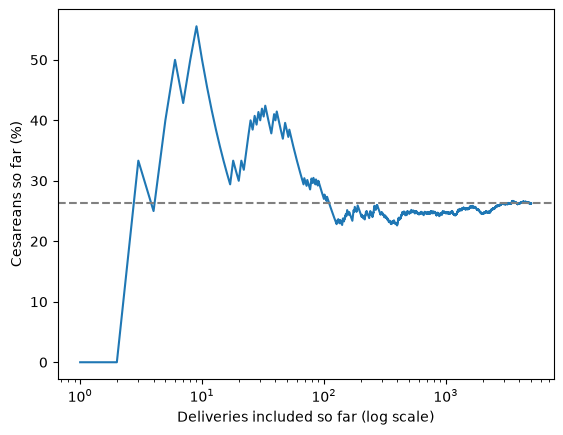

In [4]:
import matplotlib.pyplot as plt

# 1. Read the register in order: does the fraction of cesareans settle?
for k in [10, 50, 100, 500, 1000, 5000]:
    first_k = C.iloc[:k]           # the first k rows
    print("After", k, "rows:", first_k.sum(), "cesareans =", round(100 * first_k.mean(), 2), "%")

# 2. The same fraction after every row, in a plot
running = 100 * C.expanding().mean()     # % of cesareans among the rows read so far
plt.plot(range(1, n + 1), running)
plt.axhline(100 * C.mean(), color="gray", linestyle="--")      # % in the whole register
plt.xscale("log")
plt.xlabel("Deliveries included so far (log scale)")
plt.ylabel("Cesareans so far (%)")
plt.show()

### 11.3 Hemorrhage or infection: count each mother once

*How many mothers had a hemorrhage or an infection?*

In [5]:
# 1. Cross the two columns: each delivery falls in exactly one of four cells
print("Hemorrhage (rows) by infection (columns):")
print(pd.crosstab(df["hemorrhage"], df["infection"], margins=True, margins_name="Total"))

# 2. Count the mothers with each complication, and with both
n_infection = I.sum()
n_both = (H & I).sum()             # "&" means "and": both at the same time
print()
print(n_hemorrhage, "mothers had a hemorrhage and", n_infection, "had an infection.")
print("Adding the two gives", n_hemorrhage + n_infection, "but the", n_both, "mothers with both were counted twice.")

Hemorrhage (rows) by infection (columns):
infection     no  yes  Total
hemorrhage                  
no          4599  111   4710
yes          271   19    290
Total       4870  130   5000

290 mothers had a hemorrhage and 130 had an infection.
Adding the two gives 420 but the 19 mothers with both were counted twice.


### 11.3.1 Rules for combining the counts

In [6]:
# 1. Addition rule: count the mothers with both only once
print("Hemorrhage or infection:", n_hemorrhage, "+", n_infection, "-", n_both, "=", n_hemorrhage + n_infection - n_both, "mothers.")

# 2. Check by counting directly
either = H | I                     # "|" means "or": at least one of the two
n_either = either.sum()
print("Counted directly:", n_either, "of", n, "mothers =", round(100 * n_either / n, 2), "%")

# 3. Complement: the mothers with neither
print("With neither:", n - n_either, "of", n, "mothers =", round(100 * (n - n_either) / n, 2), "%")

Hemorrhage or infection: 290 + 130 - 19 = 401 mothers.
Counted directly: 401 of 5000 mothers = 8.02 %
With neither: 4599 of 5000 mothers = 91.98 %


### 11.4 Infection within each delivery group

*Is infection more frequent after a cesarean?*

In [7]:
# 1. Split the deliveries by type: cesarean, and vaginal (not cesarean)
n_vaginal = (~C).sum()             # "~" means "not"

# 2. Within each group, count the infections and divide by the size of that group
infected_cesarean = (C & I).sum()
infected_vaginal = (~C & I).sum()
print("Infection among cesarean deliveries:", infected_cesarean, "of", n_cesarean, "=", round(infected_cesarean / n_cesarean, 4))
print("Infection among vaginal deliveries:", infected_vaginal, "of", n_vaginal, "=", round(infected_vaginal / n_vaginal, 4))

Infection among cesarean deliveries: 87 of 1313 = 0.0663
Infection among vaginal deliveries: 43 of 3687 = 0.0117


### 11.4.1 The same count can answer different questions

In [8]:
# 1. The same infected cesareans over ALL deliveries (a different denominator)
print("Cesarean and infection, among all deliveries:", infected_cesarean, "of", n, "=", round(infected_cesarean / n, 4))

# 2. Infection over all deliveries, whatever the delivery type
print("Infection, among all deliveries:", n_infection, "of", n, "=", round(n_infection / n, 4))

Cesarean and infection, among all deliveries: 87 of 5000 = 0.0174
Infection, among all deliveries: 130 of 5000 = 0.026


### 11.5 Do hemorrhage and infection occur independently?

*Do hemorrhage and infection come together or independently?*

In [9]:
# 1. If hemorrhage and infection were independent, P(H and I) would equal P(H) x P(I)
p_h = n_hemorrhage / n
p_i = n_infection / n
print("Expected if independent:", round(p_h, 4), "x", round(p_i, 4), "=", round(p_h * p_i, 6))

# 2. What the register shows
print("Observed, both together:", n_both, "of", n, "=", round(n_both / n, 4))

# 3. Infection within the mothers with and without hemorrhage
print()
print("Infection among mothers with hemorrhage:", n_both, "of", n_hemorrhage, "=", round(n_both / n_hemorrhage, 4))
print("Infection among mothers without hemorrhage:", (~H & I).sum(), "of", (~H).sum(), "=", round((~H & I).sum() / (~H).sum(), 4))

Expected if independent: 0.058 x 0.026 = 0.001508
Observed, both together: 19 of 5000 = 0.0038

Infection among mothers with hemorrhage: 19 of 290 = 0.0655
Infection among mothers without hemorrhage: 111 of 4710 = 0.0236


### 11.5.1 Multiplying while retaining the conditions

In [10]:
# Cesarean, then hemorrhage among the cesareans, then infection among those
n_ch = (C & H).sum()
n_chi = (C & H & I).sum()
print("Of", n_cesarean, "cesareans,", n_ch, "had a hemorrhage, and", n_chi, "of those also had an infection.")
chain = (n_cesarean / n) * (n_ch / n_cesarean) * (n_chi / n_ch)
print("P(C) x P(H|C) x P(I|C and H) =", round(chain, 4), "; direct count:", round(n_chi / n, 4))

Of 1313 cesareans, 95 had a hemorrhage, and 14 of those also had an infection.
P(C) x P(H|C) x P(I|C and H) = 0.0028 ; direct count: 0.0028


### 11.6 Among infections, how many followed cesareans?

*Among the mothers with infection, what fraction had a cesarean?*

In [11]:
# 1. The table: rows are the delivery type, columns are infection
print("Delivery type (rows) by infection (columns):")
print(pd.crosstab(df["cesarean"], df["infection"], margins=True, margins_name="Total"))

# 2. Counting directly among the infected mothers
print()
print("Among the", n_infection, "infections,", infected_cesarean, "followed a cesarean =", round(100 * infected_cesarean / n_infection, 2), "%")

Delivery type (rows) by infection (columns):
infection    no  yes  Total
cesarean                   
no         3644   43   3687
yes        1226   87   1313
Total      4870  130   5000

Among the 130 infections, 87 followed a cesarean = 66.92 %


### 11.6.1 Reconstruct the total before reversing the condition

In [12]:
# 1. Rebuild the overall infection fraction from the two groups (total probability)
p_c = n_cesarean / n                               # P(C)
p_i_given_c = infected_cesarean / n_cesarean       # P(I|C)
p_i_given_not_c = infected_vaginal / n_vaginal     # P(I|not C)
p_i = p_i_given_c * p_c + p_i_given_not_c * (1 - p_c)
print("P(I) = P(I|C) P(C) + P(I|not C) P(not C) =", round(p_i, 4))

# 2. Reverse the condition (Bayes): from infection among cesareans to cesareans among infections
p_c_given_i = p_i_given_c * p_c / p_i
print("P(C|I) = P(I|C) P(C) / P(I) =", round(p_c_given_i, 4), "; direct count:", round(infected_cesarean / n_infection, 4))

P(I) = P(I|C) P(C) + P(I|not C) P(not C) = 0.026
P(C|I) = P(I|C) P(C) / P(I) = 0.6692 ; direct count: 0.6692


### 11.7 Choosing charts for review

*In how many ways can 20 charts be chosen, and how likely is the sample to include an infection?*

In [13]:
from math import comb, factorial, perm

total = n                          # charts in the register
without_infection = n - n_infection

# In how many ways can 20 charts be chosen? (order does not matter)
sets = comb(total, 20)
print("There are", sets, "different sets of 20 charts,", len(str(sets)), "digits.")

There are 37735558620382470911680923426535607627307325009655406000 different sets of 20 charts, 56 digits.


### 11.7.1 Does order matter?

In [14]:
# Orders of the 20 selected charts, and of the first two slots
print("The 20 chosen charts can be put in", factorial(20), "orders; the first two slots, in", perm(20, 2))

The 20 chosen charts can be put in 2432902008176640000 orders; the first two slots, in 380


### 11.7.2 Use the sample with no infections as the complement

In [15]:
# 1. Chance of at least one infection = 1 - chance of none (all 20 from the charts without infection)
chance_none = comb(without_infection, 20) / comb(total, 20)
print("Chance that 20 charts include at least one infection:", round(1 - chance_none, 4))

# 2. Smallest sample with at least 90%: try sizes 1, 2, 3, ... until the chance of none is at most 10%
size = 1
while 10 * comb(without_infection, size) > comb(total, size):     # compares whole numbers, no rounding
    size = size + 1
for m in [size - 1, size]:
    print("With", m, "charts the chance is", round(1 - comb(without_infection, m) / comb(total, m), 6))
print("So", size, "is the smallest sample with at least 90%.")

Chance that 20 charts include at least one infection: 0.4102
With 86 charts the chance is 0.898259
With 87 charts the chance is 0.90095
So 87 is the smallest sample with at least 90%.


## Part B. Exercise solutions

### 11.9 Exercise 1. Records and event descriptions

In [16]:
from itertools import product

# 1. The sample space: one of the 5,000 identifiers
print(n, "records,", df["delivery_id"].nunique(), "distinct identifiers.")

# 2. The eight descriptions (C, H, I), 1 = yes and 0 = no
print("The eight descriptions:")
for bits in product([0, 1], repeat=3):
    print(bits)

5000 records, 5000 distinct identifiers.
The eight descriptions:
(0, 0, 0)
(0, 0, 1)
(0, 1, 0)
(0, 1, 1)
(1, 0, 0)
(1, 0, 1)
(1, 1, 0)
(1, 1, 1)


### 11.9 Exercise 2. Running fractions and order

In [17]:
# 1. Fraction of cesareans among the first k records
for k in [10, 50, 100, 500, 1000, 5000]:
    print("First", k, "records:", round(100 * C.iloc[:k].mean(), 2), "%")

# 2. Reverse the register order: first 100 records, and all 5,000
reverse = C.iloc[::-1]             # the same rows, from last to first
print()
print("Reversed order: first 100 records", round(100 * reverse.iloc[:100].mean(), 2), "% ; all", n, "records", round(100 * reverse.mean(), 2), "%")

First 10 records: 50.0 %
First 50 records: 38.0 %
First 100 records: 27.0 %
First 500 records: 24.6 %
First 1000 records: 24.6 %
First 5000 records: 26.26 %

Reversed order: first 100 records 25.0 % ; all 5000 records 26.26 %


### 11.9 Exercise 3. Count the overlap once

In [18]:
# 1. The four groups: hemorrhage only, infection only, both, neither
only_h = (H & ~I).sum()
only_i = (~H & I).sum()
both = (H & I).sum()
neither = (~H & ~I).sum()
print("Hemorrhage only:", only_h, "mothers =", round(only_h / n, 4))
print("Infection only:", only_i, "mothers =", round(only_i / n, 4))
print("Both:", both, "mothers =", round(both / n, 4))
print("Neither:", neither, "mothers =", round(neither / n, 4))

# 2. Addition rule, and the same count done directly
print()
print("Addition rule:", H.sum() + I.sum() - both, "mothers with hemorrhage or infection =", round((H.sum() + I.sum() - both) / n, 4))
print("Direct count:", (H | I).sum(), "mothers")

Hemorrhage only: 271 mothers = 0.0542
Infection only: 111 mothers = 0.0222
Both: 19 mothers = 0.0038
Neither: 4599 mothers = 0.9198

Addition rule: 401 mothers with hemorrhage or infection = 0.0802
Direct count: 401 mothers


### 11.9 Exercise 4. Name the denominator

In [19]:
# 1. The five fractions: the numerator and the denominator of each
print("(a) infection among cesareans:", (C & I).sum(), "/", C.sum(), "=", round((C & I).sum() / C.sum(), 4))
print("(b) cesarean and infection, among all:", (C & I).sum(), "/", n, "=", round((C & I).sum() / n, 4))
print("(c) infection, among all:", I.sum(), "/", n, "=", round(I.sum() / n, 4))
print("(d) cesarean among infections:", (C & I).sum(), "/", I.sum(), "=", round((C & I).sum() / I.sum(), 4))
print("(e) hemorrhage among cesareans:", (C & H).sum(), "/", C.sum(), "=", round((C & H).sum() / C.sum(), 4))

(a) infection among cesareans: 87 / 1313 = 0.0663
(b) cesarean and infection, among all: 87 / 5000 = 0.0174
(c) infection, among all: 130 / 5000 = 0.026
(d) cesarean among infections: 87 / 130 = 0.6692
(e) hemorrhage among cesareans: 95 / 1313 = 0.0724


### 11.9 Exercise 5. Compare within delivery types

In [20]:
# 1. Infection in each delivery type, and the ratio of the two proportions
p_cesarean = (C & I).sum() / C.sum()
p_vaginal = (~C & I).sum() / (~C).sum()
print("Infection: cesarean", round(p_cesarean, 4), "versus vaginal", round(p_vaginal, 4), "; ratio", round(p_cesarean / p_vaginal, 4))

# 2. Hemorrhage in each delivery type: count, group size, proportion
print("Hemorrhage, cesarean:", (C & H).sum(), "of", C.sum(), "=", round((C & H).sum() / C.sum(), 4))
print("Hemorrhage, vaginal:", (~C & H).sum(), "of", (~C).sum(), "=", round((~C & H).sum() / (~C).sum(), 4))

Infection: cesarean 0.0663 versus vaginal 0.0117 ; ratio 5.6815
Hemorrhage, cesarean: 95 of 1313 = 0.0724
Hemorrhage, vaginal: 195 of 3687 = 0.0529


### 11.9 Exercise 6. Dependence and overlap

In [21]:
# 1. Product of the marginals versus the observed joint fraction
p_h, p_i = H.sum() / n, I.sum() / n
print("Product of the marginals:", round(p_h * p_i, 6), "; observed joint fraction:", round((H & I).sum() / n, 4))

# 2. Infection with and without hemorrhage, and the number with both
print("Infection with hemorrhage:", round((H & I).sum() / H.sum(), 4), "; without hemorrhage:", round((~H & I).sum() / (~H).sum(), 4))
print("Mothers with both:", (H & I).sum())

Product of the marginals: 0.001508 ; observed joint fraction: 0.0038
Infection with hemorrhage: 0.0655 ; without hemorrhage: 0.0236
Mothers with both: 19


### 11.9 Exercise 7. Two routes to the same joint probability

In [22]:
# 1. The counts along the way
n_c, n_h, n_ch, n_chi = C.sum(), H.sum(), (C & H).sum(), (C & H & I).sum()
print("Counts:", n_c, "cesareans,", n_h, "hemorrhages,", n_ch, "with both,", n_chi, "with all three.")

# 2. Two ways to order the conditions: C, H, I and H, C, I (they must agree)
first = (n_c / n) * (n_ch / n_c) * (n_chi / n_ch)
second = (n_h / n) * (n_ch / n_h) * (n_chi / n_ch)
print("Route C, H, I:", round(first, 4), "| route H, C, I:", round(second, 4), "| direct count:", round(n_chi / n, 4))

Counts: 1313 cesareans, 290 hemorrhages, 95 with both, 14 with all three.
Route C, H, I: 0.0028 | route H, C, I: 0.0028 | direct count: 0.0028


### 11.9 Exercise 8. Total probability and reversal

In [23]:
# 1. Total probability of infection from the two delivery types
p_c = C.sum() / n
p_i_given_c = (C & I).sum() / C.sum()
p_i_given_not_c = (~C & I).sum() / (~C).sum()
p_i = p_i_given_c * p_c + p_i_given_not_c * (1 - p_c)
print("Total probability of infection:", round(p_i, 4))

# 2. Bayes: cesareans among the infected, and vaginal deliveries among the infected
bayes = p_i_given_c * p_c / p_i
print("Among the infected: cesarean", round(bayes, 4), "; vaginal", round(1 - bayes, 4))
print("Direct count among the infected: cesarean", round((C & I).sum() / I.sum(), 4))

Total probability of infection: 0.026
Among the infected: cesarean 0.6692 ; vaginal 0.3308
Direct count among the infected: cesarean 0.6692


### 11.9 Exercise 9. Orders of the selected charts

In [24]:
# 1. Orders of 20 charts, and ordered first two slots
print("20! =", factorial(20), "orders; first two slots:", perm(20, 2), "ordered choices")

# 2. Chance that a given chart is first, and that two given charts are first and second
print("A given chart is first with chance", round(factorial(19) / factorial(20), 4))
print("Two given charts are first and second with chance", round(factorial(18) / factorial(20), 6))

20! = 2432902008176640000 orders; first two slots: 380 ordered choices
A given chart is first with chance 0.05
Two given charts are first and second with chance 0.002632


### 11.9 Exercise 10. A sample including an infection

In [25]:
# 1. Smallest sample with at least 90% chance of including an infection (uses comb, total, without_infection from 11.7)
size = 1
while 10 * comb(without_infection, size) > comb(total, size):
    size = size + 1

# 2. The chance for a sample of 20, for the size just below, and for the smallest size
for m in [20, size - 1, size]:
    print(m, "charts: chance of at least one infection =", round(1 - comb(without_infection, m) / comb(total, m), 6))

20 charts: chance of at least one infection = 0.410156
86 charts: chance of at least one infection = 0.898259
87 charts: chance of at least one infection = 0.90095


### 11.9 Exercise 11. Alternative marginal probabilities (alt.)

In [26]:
# 1. Alternative marginals: P(H) = 0.02 and P(I) = 0.03
p_h = 0.02
p_i = 0.03

# 2. Smallest and largest possible joint probability, and P(H or I) if independent
lower = max(p_h, p_i)
upper = min(1, p_h + p_i)
print("The joint probability must lie between", lower, "and", upper)
print("If the events were independent, P(H or I) =", round(p_h + p_i - p_h * p_i, 4))

The joint probability must lie between 0.03 and 0.05
If the events were independent, P(H or I) = 0.0494


### 11.9 Exercise 12. Returning charts between draws (alt.)

In [27]:
# 1. Chance of at least one infection in 20 draws, with and without returning the chart
with_replacement = 1 - (without_infection / total) ** 20
without_replacement = 1 - comb(without_infection, 20) / comb(total, 20)
print("Returning each chart:", round(with_replacement, 6), "| not returning:", round(without_replacement, 6))

# 2. The difference between the two procedures
print("The difference is only", round(without_replacement - with_replacement, 6))

Returning each chart: 0.409555 | not returning: 0.410156
The difference is only 0.0006


---
*Synthetic data (seed 11, `generate_data.py`). Teaching values only; nothing here is a clinical recommendation or an estimate for a real unit.*